# Figure 3: Measuring the bound

How the decision bound is measured directly from each trial, how those direct
measures relate to the stopping model's fitted bound, and what the model says
about the bound and about the sources of commitments. Main figure: OL, low-SNR
block 2 (raw block numbering; coin-penalty condition).

**Panels**

- **A. Direct measure and model bound, one trial.** The pigeon's position over
  the trial, the key press, the NDT period, and the direct bound estimate
  (`get_bounds`: the midpoint of the positions at DT − 1 and DT, the step the
  subject is inferred to have committed at). Behind it, that subject's fitted
  mean bound (knee form: high at step 1, falling to the **bound plateau** at the
  knee, then a slow decline) with the interquartile range of the trial-to-trial
  bound variability.
- **B. Example subject.** Per-trial measured |bound| vs. DT; the model's
  prediction for the *measured* bound (each subject simulated from their fit
  and run through the same `get_bounds` pipeline); and the model's actual bound
  at that step.
- **C. Bound shape.** Each subject's fitted time course relative to their
  plateau (thin blue; the shape is shared across a subject's blocks), the
  median across subjects (thick black), and each subject's knee step (ticks).
- **D. All subjects.** Z-scored measured |bound| vs. DT, data and model
  (simulated, measured the same way). DT = 1 is shown (normally excluded by
  the DT ≥ 2 filter, dotted line).
- **E. Direct measure, data vs. model.** Per subject: the median measured
  |bound| (raw positions, the standard trial filter) in the data against the
  same quantity in the model's simulated data.
- **F. Sources of commitments.** From the simulated data (where each commit's
  source is known): bound crossings, early guesses (commits
  inside the bound, including start-frame guesses) and pure guesses (key
  presses on the first frame, before anything shown could be processed), on all trials and on trials passing the standard filter;
  hatching marks lapses (random choice).

**Excluded:** subject-blocks whose plateau sits at a fit limit or above the screen edge (0.75)
(`get_plateau_edge_fit`: choices not from bound crossings); counts are printed.

**Conventions:** black = data (and medians: the data median in B, the
across-subject median in C), blue = model; solid blue = model bound, dashed
blue = model estimate (simulated data measured like the real data).

**Data.** Trials from `get_stopping_model_trials('OL', 1–6)` (the trials the
model was fit to: trial_number ≥ 10, recorded choice; raw
positions, no bias correction). Direct measures (B, D, E) additionally use the
standard filter `get_good_trial_array` (DT ≥ 2, or ≥ 1 in D; no wall hit; RT
cutoff). Fits: `data/processed/stopping_fits_main.pkl` (from
`scripts/run_stopping_fits.py`).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.legend_handler import HandlerTuple
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_good_trial_array
from pigeon.path_defaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, GUESS_COLOR, LAPSE_BAR, MODEL_COLOR, SUBJECT_MARKER, TRIAL_MARKER,
                             add_panel_label, format_p, format_rho, use_figure_style)
from pigeon.stopping import (bound_time_course, get_log_h, get_plateau_edge_fit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = DATA_DIR

## Data, fits and simulated data

Each subject's trials (all six OL blocks, so that `get_bounds`' per-subject NDT
estimate and RT cutoffs see the same trials as for the real data) are
simulated `SIM_REPS` times from the subject's fitted parameters, then run
through the real-data bound pipeline (`infer_bounds_like_data`). Simulated
trials take `trial_number = 99`: they replace trials that already passed the
trial-number exclusion.

In [2]:
BLOCK = 'B2'          # raw OL block 2: low SNR, coin penalty
EXAMPLE_SUBJECT = 16
SIM_REPS = 10
SIM_SEED = 3
DTS = np.arange(1, 11)

trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
get_stopping_model_trials('MX', [1, 2, 3])   # cohort 2's fitted trials: printed only, for the Methods' exclusion counts
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim).assign(trial_number=99)

# Subject-blocks whose plateau sits at a fit limit or above the screen edge (0.75) make choices that do not come from bound crossings (see
# get_plateau_edge_fit); they are left out of every panel here.
fits_b = fits[fits.group == BLOCK].set_index('subject_index')
l_limit = get_plateau_edge_fit(fits_b)
print(f'{BLOCK}: excluded {int(l_limit.sum())} of {len(fits_b)} subjects with an edge fit (plateau at a fit limit or > 0.75): '
      f'{fits_b.bound_scale[l_limit].round(3).to_dict()}')
fits_b = fits_b[~l_limit]
real_b = trials[(trials.condition == BLOCK) & trials.subject_index.isin(fits_b.index)]
sim_b = sim[(sim.condition == BLOCK) & sim.subject_index.isin(fits_b.index)]
print(f'{BLOCK}: {len(real_b):,} real trials, {len(sim_b):,} simulated ({SIM_REPS} per real trial), '
      f'{len(fits_b)} subjects')

OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 365 more with no choice; 60 subjects


MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 182 more with no choice; 60 subjects


B2: excluded 5 of 60 subjects with an edge fit (plateau at a fit limit or > 0.75): {6: 0.778, 22: 1.067, 44: 1.839, 51: 2.0, 59: 0.885}
B2: 3,862 real trials, 38,620 simulated (10 per real trial), 55 subjects


## Panel statistics

- **D:** per subject, |bound| is z-scored over that subject's trials passing the
  filter (DT ≥ 1, DT ≤ 10), then averaged per DT; subjects with < 5 trials are
  skipped (reported).
- **E:** median |bound| per subject over trials passing the standard filter
  with a finite, nonzero bound; the model's
  median pools that subject's simulated repetitions.
- **F:** fractions of all simulated trials, and of those passing the standard
  filter (DT ≥ 2).
- **Text only, left vs. right choices:** per subject, |bound| on right- vs. left-choice trials
  (standard filter, finite nonzero bound), Mann–Whitney U (rank-sum) test; subjects need ≥ 3 trials of
  each choice. Reported: subjects with p < 0.01 and with p < 0.05 after Bonferroni correction, and a
  signed-rank test across subjects of the right − left median difference.


In [3]:
def _measured(t, min_dt):
    lg = get_good_trial_array(t, min_dt=min_dt) & np.isfinite(t.bound) & (t.bound != 0)
    return t[lg]

def _z_by_dt(t, min_trials=5):
    t = _measured(t, 1)
    t = t[t.DT <= DTS[-1]]
    curves, skipped = {}, []
    for subject, g in t.groupby('subject_index'):
        if len(g) < min_trials:
            skipped.append(subject)
            continue
        z = (g.abs_bound - g.abs_bound.mean()) / g.abs_bound.std(ddof=0)
        curves[subject] = z.groupby(g.DT).mean().reindex(DTS)
    return pd.DataFrame(curves).T, skipped

z_real, skip_real = _z_by_dt(real_b)
z_sim, skip_sim = _z_by_dt(sim_b)
print(f'D: {len(z_real)} subjects (skipped, < 5 trials: real {skip_real}, model {skip_sim})')
print(pd.DataFrame({'data': z_real.mean(), 'model': z_sim.mean()}).T.round(2))

med = pd.DataFrame({'plateau': fits_b.bound_scale,
                    'data': _measured(real_b, 2).groupby('subject_index').abs_bound.median(),
                    'model': _measured(sim_b, 2).groupby('subject_index').abs_bound.median()})
print(f"\nE: Spearman r, plateau vs. median measured |bound|: data {scipy.stats.spearmanr(med.plateau, med.data)[0]:.2f}, "
      f"model {scipy.stats.spearmanr(med.plateau, med.model)[0]:.2f}; "
      f"data vs. model medians {scipy.stats.spearmanr(med.data, med.model)[0]:.2f} "
      f"(Pearson {np.corrcoef(med.data, med.model)[0, 1]:.2f})")
print(f'   median plateau {med.plateau.median():.3f}; median of medians: data {med.data.median():.3f}, '
      f'model {med.model.median():.3f}')
tercile = pd.qcut(fits_b.bound_scale, 3, labels=['low', 'middle', 'high'])
print('   wall-hit fraction by plateau tercile (real trials):',
      real_b.groupby(real_b.subject_index.map(tercile), observed=True).wall_hit.mean().round(3).to_dict())

SOURCES = ['bound', 'guess', 'anticipation']
l_pass = get_good_trial_array(sim_b, min_dt=2)
def _sources(t):
    frac = t.commit_type.value_counts(normalize=True).reindex(SOURCES, fill_value=0.0)
    lapse = t.groupby('commit_type').lapse.mean().reindex(SOURCES, fill_value=0.0)
    return pd.DataFrame({'fraction': frac, 'of which lapse': lapse})
src = {'All trials': _sources(sim_b), 'DT ≥ 2 filter': _sources(sim_b[l_pass])}
print(f'\nF: {l_pass.mean():.1%} of simulated trials pass the filter; no commits hit the step cap: '
      f'{(sim_b.commit_type == "cap").sum() == 0}')
display(pd.concat(src, axis=1).round(3))
print('lapses overall:', {k: round(float(t.lapse.mean()), 3) for k, t in (('all', sim_b), ('filter', sim_b[l_pass]))})

D: 52 subjects (skipped, < 5 trials: real [35, 42, 55], model [])
DT       1     2     3     4     5     6     7     8     9     10
data  -1.11 -0.28  0.18  0.13  0.11  0.27 -0.01  0.02  0.04 -0.04
model -1.34 -0.36 -0.01  0.17  0.24  0.22  0.24  0.24  0.20  0.20

E: Spearman r, plateau vs. median measured |bound|: data 0.79, model 0.78; data vs. model medians 0.91 (Pearson 0.87)
   median plateau 0.422; median of medians: data 0.307, model 0.312
   wall-hit fraction by plateau tercile (real trials): {'low': 0.054, 'middle': 0.131, 'high': 0.327}

F: 70.5% of simulated trials pass the filter; no commits hit the step cap: True


All trials                DT ≥ 2 filter               
               fraction of which lapse      fraction of which lapse
commit_type                                                        
bound             0.856          0.081         0.914          0.076
guess             0.112          0.128         0.086          0.103
anticipation      0.033          0.000         0.000          0.000

lapses overall: {'all': 0.084, 'filter': 0.078}


In [4]:
# Text only: does the measured |bound| differ between right and left choices?
MIN_PER_SIDE = 3
lr_rows = []
for subject, g in _measured(real_b, 2).groupby('subject_index'):
    right, left = g.abs_bound[g.choice == 1], g.abs_bound[g.choice == 0]
    if min(len(right), len(left)) < MIN_PER_SIDE:
        continue
    lr_rows.append({'subject_index': subject, 'diff': right.median() - left.median(),
                    'p': scipy.stats.mannwhitneyu(right, left).pvalue})
lr = pd.DataFrame(lr_rows)
n_lr = len(lr)
print(f'Left vs. right: {n_lr} subjects tested ({len(fits_b) - n_lr} with < {MIN_PER_SIDE} trials of a choice); '
      f'p < 0.01: {(lr.p < 0.01).sum()}; Bonferroni p < 0.05: {(lr.p < 0.05 / n_lr).sum()} '
      f'(subjects {lr.subject_index[lr.p < 0.05 / n_lr].tolist()})')
print(f'   right − left median |bound|, median [IQR] {lr["diff"].median():.3f} '
      f'[{lr["diff"].quantile(0.25):.3f}, {lr["diff"].quantile(0.75):.3f}]; '
      f'signed-rank across subjects {format_p(scipy.stats.wilcoxon(lr["diff"]).pvalue)}')


Left vs. right: 53 subjects tested (2 with < 3 trials of a choice); p < 0.01: 1; Bonferroni p < 0.05: 1 (subjects [41])
   right − left median |bound|, median [IQR] 0.001 [-0.042, 0.022]; signed-rank across subjects p=0.586


## Figure

A: subject 16, trial 30: RT 7, DT 5, direct estimate -0.386; plateau 0.414, knee 2.15, h(1) 2.13, bound CV 0.125
C: median [IQR] h(1) 2.77 [2.05, 3.27], knee 2.46 [2.14, 3.38], late change per 10 steps -0.268 [-0.451, -0.143]; 55 subjects
E: Spearman rho = 0.907, p = 1.3e-21, n = 55
E: max median |position|: data 0.616, model 0.530


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


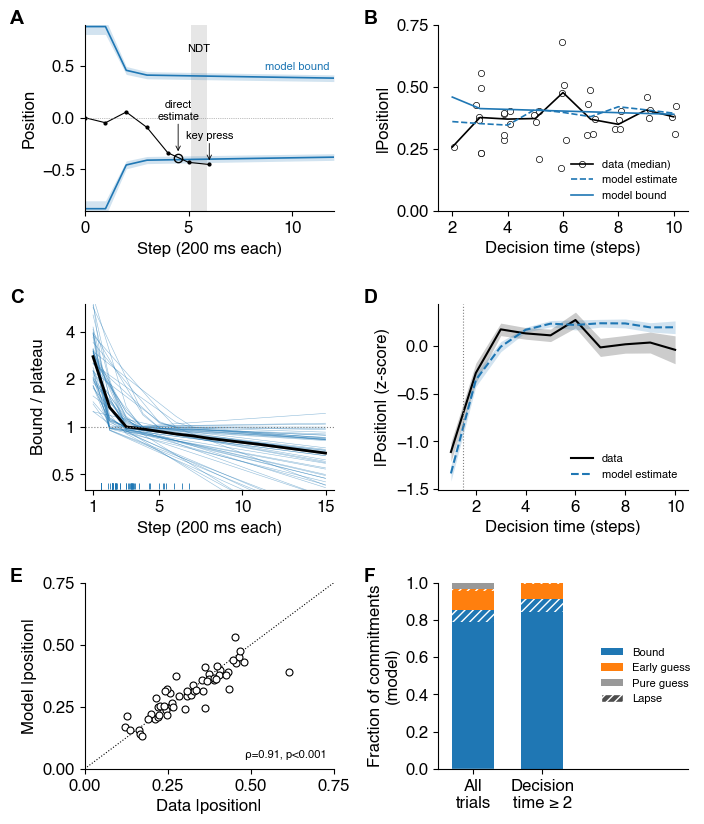

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03.pdf (+ .png)


In [5]:
use_figure_style()
GR = (0.8, 0.8, 0.8)

fig = plt.figure(figsize=(17.6 * CM, 21 * CM))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.42, left=0.11, right=0.98, bottom=0.07, top=0.97)
ax_A, ax_B, ax_C, ax_D, ax_E, ax_F = (fig.add_subplot(gs[r, c]) for r in range(3) for c in range(2))

# A: one example trial: positions, direct estimate, NDT, key press, the subject's fitted bound.
fe = fits_b.loc[EXAMPLE_SUBJECT]
ex = _measured(real_b[real_b.subject_index == EXAMPLE_SUBJECT], 2)
cand = ex[ex.DT.between(4, 6) & (ex.correct == 1)]
trial = cand.iloc[(cand.abs_bound - ex.abs_bound.median()).abs().argsort()].iloc[0]  # typical bound, mid DT
x = np.asarray(trial.steps, float)
steps = np.arange(0, 13)
theta = bound_time_course(fe, np.maximum(steps, 1))
q = scipy.stats.gamma.ppf([0.25, 0.75], a=1 / fe.bound_cv ** 2, scale=fe.bound_cv ** 2)
for sgn in (1, -1):
    ax_A.fill_between(steps, sgn * theta * q[0], sgn * theta * q[1], color=MODEL_COLOR, alpha=0.2, lw=0)
    ax_A.plot(steps, sgn * theta, color=MODEL_COLOR, lw=1.2)
dt, rt_step = int(trial.DT), len(x) - 1
ax_A.axvspan(dt + 0.1, rt_step - 0.1, color='0.9', lw=0, zorder=0)
ax_A.plot(np.arange(len(x)), x, 'k.-', lw=0.8, ms=4)
ax_A.plot(dt - 0.5, trial.bound, 'o', mfc='none', mec='k', ms=6, mew=1.0)
ax_A.axhline(0, color='0.5', lw=0.5, ls=':')
# Label on the zero side of the estimate (inside the bounds), clear of the x axis.
s = np.sign(trial.bound)
ax_A.annotate('direct\nestimate', (dt - 0.5, trial.bound - 0.06 * s), (dt - 0.5, trial.bound - 0.35 * s),
              fontsize=FS_INSET, ha='center', va='bottom' if s < 0 else 'top',
              arrowprops=dict(arrowstyle='->', lw=0.6, shrinkA=0, shrinkB=0))
# Above the band, clear of the bound and of the 'direct estimate' label below the trace.
ax_A.text((dt + rt_step) / 2, 0.62, 'NDT', fontsize=FS_INSET, ha='center', va='bottom')
# Vertical arrow from above, so the pointer can't be mistaken for another step of the trace.
ax_A.annotate('key press', (rt_step, x[-1] + 0.04), (rt_step, x[-1] + 0.25), fontsize=FS_INSET, ha='center',
              arrowprops=dict(arrowstyle='->', lw=0.6, shrinkA=0, shrinkB=0))
ax_A.text(11.8, theta[-1] + 0.06, 'model bound', color=MODEL_COLOR, fontsize=FS_INSET, ha='right', va='bottom')
ax_A.set_xlim(0, 12)
ax_A.set_ylim(-0.9, 0.9)
ax_A.set_xlabel('Step (200 ms each)')
ax_A.set_ylabel('Position')
print(f'A: subject {EXAMPLE_SUBJECT}, trial {int(trial.trial_number)}: RT {int(trial.RT)}, DT {dt}, '
      f'direct estimate {trial.bound:.3f}; plateau {fe.bound_scale:.3f}, knee {fe.knee:.2f}, '
      f'h(1) {np.exp(fe.log_h_start):.2f}, bound CV {fe.bound_cv:.3f}')

# B: example subject, measured |bound| vs. DT, with the model's measured and actual bound.
ex_sim = _measured(sim_b[sim_b.subject_index == EXAMPLE_SUBJECT], 2)
dts_b = DTS[1:]
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(ex))
# One subject's ~40 trials (little overlap): white-filled, beneath the lines.
pts_B, = ax_B.plot(ex.DT + jitter, ex.abs_bound, **{**TRIAL_MARKER, 'ms': 4.5, 'mfc': 'w'}, zorder=1)
med_B, = ax_B.plot(dts_b, ex.groupby('DT').abs_bound.median().reindex(dts_b), 'k-', lw=1.2)
ax_B.plot(dts_b, ex_sim.groupby('DT').abs_bound.median().reindex(dts_b), '--', color=MODEL_COLOR, lw=1.2,
          label='model estimate')
ax_B.plot(dts_b, bound_time_course(fe, dts_b), '-', color=MODEL_COLOR, lw=1.2, label='model bound')
ax_B.set_xlim(1.5, 10.5)
ax_B.set_ylim(0, 0.75)
ax_B.set_yticks([0, 0.25, 0.5, 0.75])
ax_B.set_xticks([2, 4, 6, 8, 10])
ax_B.set_xlabel('Decision time (steps)')
ax_B.set_ylabel('|Position|')
# The data entry shows a trial point beneath the median line, as in the panel.
h_B, l_B = ax_B.get_legend_handles_labels()
ax_B.legend([(pts_B, med_B), *h_B], ['data (median)', *l_B], handler_map={tuple: HandlerTuple(ndivide=1)},
            fontsize=FS_INSET, frameon=False, loc='lower right')

# C: bound shape relative to the plateau, one curve per subject (shape shared across blocks).
shape_steps = np.arange(1, 16)
shapes = np.exp(get_log_h(fits_b, shape_steps))
ax_C.plot(shape_steps, shapes.T, color=MODEL_COLOR, lw=0.4, alpha=0.5)
ax_C.plot(shape_steps, np.median(shapes, axis=0), 'k-', lw=2)
ax_C.axhline(1, color='0.5', ls=':', lw=0.8)
ax_C.plot(fits_b.knee, np.full(len(fits_b), 0.42), '|', color=MODEL_COLOR, ms=4, mew=0.6)   # knee rug
ax_C.set_yscale('log')
ax_C.set_ylim(0.4, 6)
ax_C.set_yticks([0.5, 1, 2, 4])
ax_C.set_yticklabels(['0.5', '1', '2', '4'])
ax_C.minorticks_off()
ax_C.set_xlim(0.5, 15.5)
ax_C.set_xticks([1, 5, 10, 15])
ax_C.set_xlabel('Step (200 ms each)')
ax_C.set_ylabel('Bound / plateau')
h1, knee, late = np.exp(fits_b.log_h_start), fits_b.knee, np.exp(10 * fits_b.late_slope) - 1
print(f'C: median [IQR] h(1) {h1.median():.2f} [{h1.quantile(.25):.2f}, {h1.quantile(.75):.2f}], '
      f'knee {knee.median():.2f} [{knee.quantile(.25):.2f}, {knee.quantile(.75):.2f}], '
      f'late change per 10 steps {late.median():.3f} [{late.quantile(.25):.3f}, {late.quantile(.75):.3f}]; '
      f'{len(fits_b)} subjects')

# D: all subjects, z-scored measured |bound| vs. DT.
for z, color, ls, label in ((z_real, 'k', '-', 'data'), (z_sim, MODEL_COLOR, '--', 'model estimate')):
    m, e = z.mean(), z.sem()
    ax_D.fill_between(DTS, m - e, m + e, color=color, alpha=0.2, lw=0)
    ax_D.plot(DTS, m, ls, color=color, lw=1.5, label=label)
ax_D.axvline(1.5, color='0.5', ls=':', lw=0.8)
ax_D.set_xlim(0.5, 10.5)
ax_D.set_xticks([2, 4, 6, 8, 10])
ax_D.set_xlabel('Decision time (steps)')
ax_D.set_ylabel('|Position| (z-score)')
ax_D.legend(fontsize=FS_INSET, frameon=False, loc='lower right')

# E: per-subject median |position| at the inferred commit step: data vs. model estimate.
E_MAX = 0.75
ax_E.plot([0, E_MAX], [0, E_MAX], 'k:', lw=0.8)
ax_E.plot(med.data, med.model, **SUBJECT_MARKER)
ax_E.set_xlim(0, E_MAX)
ax_E.set_ylim(0, E_MAX)
ax_E.set_xticks([0, 0.25, 0.5, 0.75])
ax_E.set_yticks([0, 0.25, 0.5, 0.75])
ax_E.set_xlabel('Data |position|')
ax_E.set_ylabel('Model |position|')
rho_e, p_e = scipy.stats.spearmanr(med.data, med.model)
ax_E.text(0.97, 0.05, f'{format_rho(rho_e)}, {format_p(p_e)}', transform=ax_E.transAxes,
          ha='right', va='bottom', fontsize=FS_INSET)
print(f'E: Spearman rho = {rho_e:.3f}, p = {p_e:.2g}, n = {len(med)}')
print(f'E: max median |position|: data {med.data.max():.3f}, model {med.model.max():.3f}')

# F: sources of commitments (simulated ground truth); hatching = lapse (random choice).
SRC_COLORS = {'bound': MODEL_COLOR, 'guess': GUESS_COLOR, 'anticipation': '0.6'}
SRC_LABELS = {'bound': 'Bound', 'guess': 'Early guess', 'anticipation': 'Pure guess'}
for xi, (label, s) in enumerate(src.items()):
    bottom = 0.0
    for k in SOURCES:
        h = s.loc[k, 'fraction']
        ax_F.bar(xi, h, bottom=bottom, color=SRC_COLORS[k], width=0.6, lw=0)
        hl = h * s.loc[k, 'of which lapse']
        ax_F.bar(xi, hl, bottom=bottom + h - hl, color='none', edgecolor=LAPSE_BAR['edgecolor'], hatch=LAPSE_BAR['hatch'],
                 width=0.6, lw=0)
        bottom += h
for k in SOURCES:
    ax_F.bar(0, 0, color=SRC_COLORS[k], label=SRC_LABELS[k])
ax_F.bar(0, 0, **LAPSE_BAR, label='Lapse')
ax_F.set_xticks([0, 1])
ax_F.set_xticklabels(['All\ntrials', 'Decision\ntime ≥ 2'])
ax_F.set_xlim(-0.5, 3.1)
ax_F.set_ylim(0, 1)
ax_F.set_ylabel('Fraction of commitments\n(model)')
ax_F.legend(fontsize=FS_INSET, frameon=False, loc='center right', bbox_to_anchor=(1.05, 0.5))

for ax, label in zip((ax_A, ax_B, ax_C, ax_D, ax_E, ax_F), 'ABCDEF'):
    ax.spines[['top', 'right']].set_visible(False)
    add_panel_label(ax, label, dx=-0.3)

out = FIGURES_DIR / 'Figure03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')